In [1]:
import os

from typing import Annotated, List
from typing_extensions import TypedDict
from pydantic import BaseModel
from langchain_community.vectorstores import FAISS
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_core.documents import Document
from langgraph.graph import StateGraph, END, START

/var/folders/12/zt3xcr4d475gzrfc596w39xm0000gn/T/ipykernel_64720/33222795.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

llm = ChatOpenAI(model="gpt-4o-mini")
llm


ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.8.0', 'langchain': '1.5.0', 'langchain-openai': '1.7.4'}}, profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x13f3f97f0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x13f3fa270>, root_client=<openai.OpenAI object at 0x13f3f8980>, root_async_client=<

In [3]:
urls = ["https://en.wikipedia.org/wiki/LangChain",
        "https://en.wikipedia.org/wiki/Retrieval-augmented_generation"]

loaders = [WebBaseLoader(url) for url in urls]

docs = []

for loader in loaders:
    docs.extend(loader.load())

docs



[Document(metadata={'source': 'https://en.wikipedia.org/wiki/LangChain', 'title': 'LangChain - Wikipedia', 'language': 'en'}, page_content='\n\n\n\nLangChain - Wikipedia\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nJump to content\n\n\n\n\n\n\n\nMain menu\n\n\n\n\n\nMain menu\nmove to sidebar\nhide\n\n\n\n\t\tNavigation\n\t\n\n\nMain pageContentsCurrent eventsRandom articleAbout WikipediaContact us\n\n\n\n\n\n\t\tContribute\n\t\n\n\nHelpLearn to editCommunity portalRecent changesUpload fileSpecial pages\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nSearch\n\n\n\n\n\n\n\n\n\n\n\nSearch\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nAppearance\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nDonate\n\nCreate account\n\nLog in\n\n\n\n\n\n\n\n\nPersonal tools\n\n\n\n\n\n\nDonate\n\n\nCreate account\n\n\nLog in\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\nContents\nmove to sidebar\nhide\n\n\n\n\n(Top)\n\n\n\n\n\n1\nHistory\n\n\n\n\n\n\n\n\n2\nCapabilities\n\n\n\n\n\n\n\n\n3\nLangChain tool

In [5]:
splitters = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=30
)

split_docs = splitters.split_documents(docs)

embeddeding = OpenAIEmbeddings(model="text-embedding-3-small")
vectorstore = FAISS.from_documents(split_docs, embeddeding)

retriever = vectorstore.as_retriever()

retriever

VectorStoreRetriever(tags=['FAISS', 'OpenAIEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x172200590>, search_kwargs={})

In [6]:
retriever.invoke("What is langgraph?")

[Document(id='7f00c136-312e-4167-950d-a05fe418a446', metadata={'source': 'https://en.wikipedia.org/wiki/LangChain', 'title': 'LangChain - Wikipedia', 'language': 'en'}, page_content='In February 2024 LangChain released LangSmith, a closed-source observability and evaluation platform for LLM applications, and announced a US $25 million Series A led by Sequoia Capital.[8] On 14 May 2025 the company launched LangGraph Platform into general availability, providing managed infrastructure for deploying long-running, stateful AI agents.[9]\nIn April 2025, LangChain was featured in the Forbes AI 50 list.[10]'),
 Document(id='c2fa3764-3dc2-4421-8ed8-dcd65b755832', metadata={'source': 'https://en.wikipedia.org/wiki/LangChain', 'title': 'LangChain - Wikipedia', 'language': 'en'}, page_content="Free and open-source software portal\nLangChain is a software framework that helps facilitate the integration of large language models (LLMs) into applications. As a language model integration framework, La

In [7]:
class State(BaseModel):
    question: str
    retrieved_docs: List[Document] = []
    answer: str

def retrieve_docs(state: State) -> State:
    docs = retriever.invoke(state.question)
    return State(question=state.question, retrieved_docs=docs)

def generate_answer(state: State) -> State:
    context = "\n\n".join([doc.page_content for doc in state.retrieved_docs])
    prompt = f"Answer the question based on the context. \n\nContext:\n{context}\n\nQuestion: {state.question}"
    response = llm.invoke(prompt)
    return State(question=state.question, retrieved_docs=state.retrieved_docs, answer=response.context)


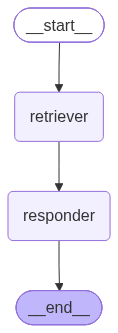

In [8]:
builder = StateGraph(State)
builder.add_node("retriever", retrieve_docs)
builder.add_node("responder", generate_answer)
builder.set_entry_point("retriever")
builder.add_edge("retriever", "responder")
builder.add_edge("responder", END)

graph = builder.compile()
graph